# Hospital Beds Management: Improving Hospital Admission Efficiency

**Student Name:** Sunny Kumar  
**Roll Number:** 26PGDM031  
**Programme:** PGDM – First Year  
**Faculty:** Dr. Wajid Ali  
**Subject:** Data Analytics for Managers Using Python

## 1. Business Problem

Hospitals need to manage patient admissions and bed availability efficiently. When patient demand is high and resources are limited, some patients may not receive admission.

In this project, I am analysing hospital management data to understand the factors associated with patient admission refusals. My main focus is on patient demand, bed availability and differences between hospital departments.

## 2. Dataset Information

**Dataset Name:** Hospital Beds Management

**Source:** https://www.kaggle.com/datasets/jaderz/hospital-beds-management

The dataset contains information about patients, hospital services, staff and staff schedules.

## 3. Project Objectives

1. Analyse hospital patient demand, admissions and refusals.
2. Examine bed availability and department-wise performance.
3. Identify patterns using descriptive statistics and visualisations.
4. Develop two multiple linear regression models, with and without interaction terms.
5. Compare both models and recommend practical improvements for hospital management.

In [1]:

from google.colab import files

uploaded = files.upload()


Saving patients.csv to patients.csv
Saving services_weekly.csv to services_weekly.csv
Saving staff_schedule.csv to staff_schedule.csv
Saving staff.csv to staff.csv


In [3]:
import pandas as pd
import numpy as np

patients = pd.read_csv("patients.csv")
services = pd.read_csv("services_weekly.csv")
schedule = pd.read_csv("staff_schedule.csv")
staff = pd.read_csv("staff.csv")

print("Patients:", patients.shape)
print("Services:", services.shape)
print("Schedule:", schedule.shape)
print("Staff:", staff.shape)

display(services.head())

services.info()

Patients: (1000, 7)
Services: (208, 10)
Schedule: (6552, 6)
Staff: (110, 4)


,week,month,service,available_beds,patients_request,patients_admitted,patients_refused,patient_satisfaction,staff_morale,event
0,1,1,emergency,32,76,32,44,67,70,none
1,1,1,surgery,45,130,45,85,83,78,flu
2,1,1,general_medicine,37,201,37,164,97,43,flu
3,1,1,ICU,22,31,22,9,84,91,flu
4,2,1,emergency,28,169,28,141,75,64,none


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   week                  208 non-null    int64 
 1   month                 208 non-null    int64 
 2   service               208 non-null    object
 3   available_beds        208 non-null    int64 
 4   patients_request      208 non-null    int64 
 5   patients_admitted     208 non-null    int64 
 6   patients_refused      208 non-null    int64 
 7   patient_satisfaction  208 non-null    int64 
 8   staff_morale          208 non-null    int64 
 9   event                 208 non-null    object
dtypes: int64(8), object(2)
memory usage: 16.4+ KB


In [5]:

# Step 4: Check missing values and duplicates

datasets = {
    "Patients": patients,
    "Services": services,
    "Staff Schedule": schedule,
    "Staff": staff
}

for name, df in datasets.items():
    print("\nDataset:", name)

    print("Missing values:")
    print(df.isnull().sum())

    print("Duplicate rows:", df.duplicated().sum())

    print("-" * 40)



Dataset: Patients
Missing values:
patient_id        0
name              0
age               0
arrival_date      0
departure_date    0
service           0
satisfaction      0
dtype: int64
Duplicate rows: 0
----------------------------------------

Dataset: Services
Missing values:
week                    0
month                   0
service                 0
available_beds          0
patients_request        0
patients_admitted       0
patients_refused        0
patient_satisfaction    0
staff_morale            0
event                   0
dtype: int64
Duplicate rows: 0
----------------------------------------

Dataset: Staff Schedule
Missing values:
week          0
staff_id      0
staff_name    0
role          0
service       0
present       0
dtype: int64
Duplicate rows: 0
----------------------------------------

Dataset: Staff
Missing values:
staff_id      0
staff_name    0
role          0
service       0
dtype: int64
Duplicate rows: 0
----------------------------------------


week : 0 outliers
month : 0 outliers
available_beds : 1 outliers
patients_request : 10 outliers
patients_admitted : 2 outliers
patients_refused : 14 outliers
patient_satisfaction : 0 outliers
staff_morale : 0 outliers


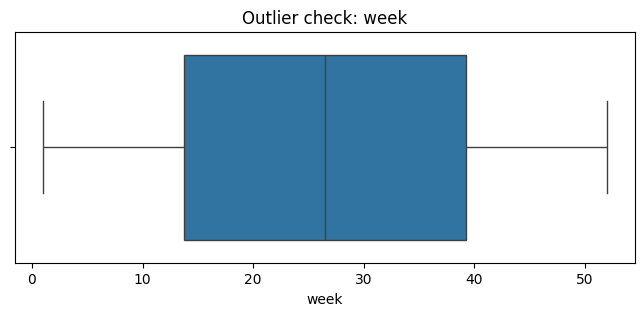

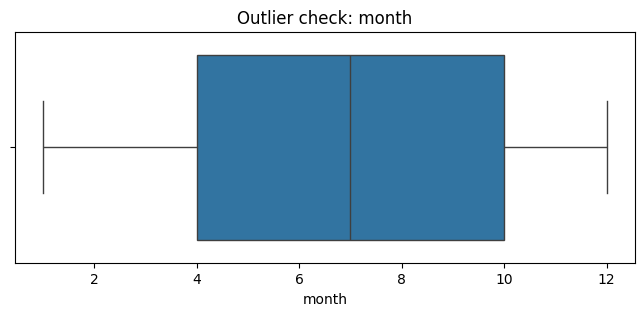

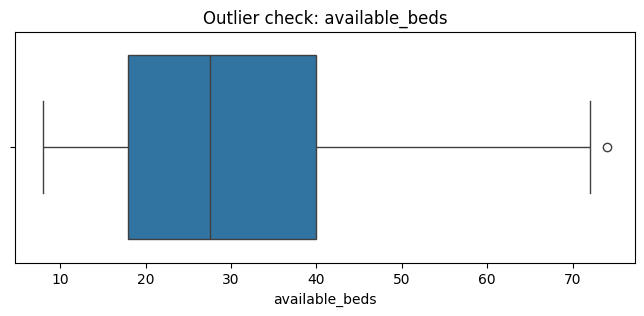

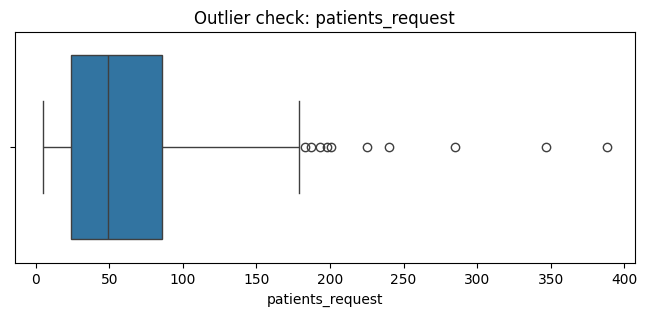

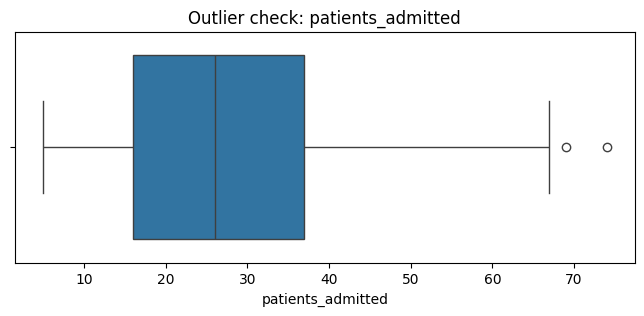

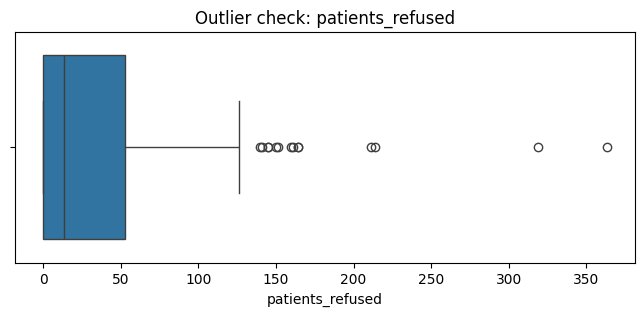

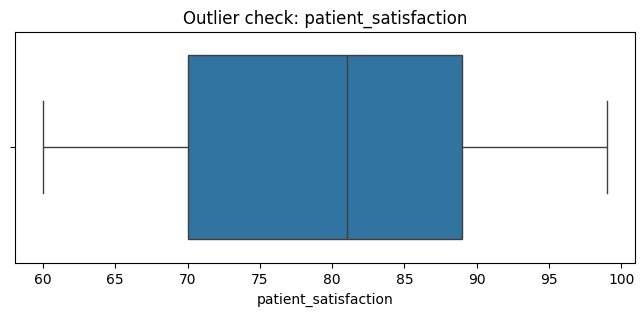

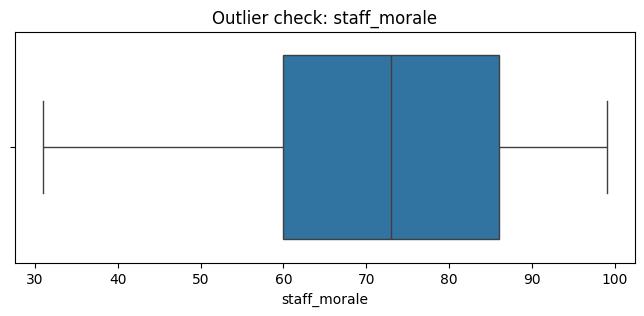

In [6]:

# Step 5: Detect outliers using IQR

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns from the services dataset
numeric_cols = services.select_dtypes(include="number").columns

for col in numeric_cols:
    Q1 = services[col].quantile(0.25)
    Q3 = services[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = services[
        (services[col] < lower) |
        (services[col] > upper)
    ]

    print(col, ":", len(outliers), "outliers")

# Draw box plots
for col in numeric_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=services[col])
    plt.title("Outlier check: " + col)
    plt.xlabel(col)
    plt.show()


### Outlier Detection and Treatment

I used the Interquartile Range (IQR) method to identify unusual values in the hospital services dataset.

The analysis identified 14 outliers in patient refusals, 10 in patient requests, 2 in patients admitted and 1 in available beds.

I decided to retain these observations because unusually high patient demand or refusals may represent important operational situations in a hospital.

Removing these records without further investigation could hide useful information about admission pressure.

However, these values should be verified before making major management decisions. Since the IQR analysis was performed across all departments together, some flagged values may also reflect normal differences between departments.

Therefore, I retained the observations for further analysis rather than automatically deleting them.

In [38]:

# Step 6: Descriptive Statistics

display(services.describe().round(2))

# Calculate median
print("\nMedian:")
print(services.select_dtypes(include="number").median())

# Calculate mode
# Calculate mode for important hospital variables
print("\nMode (Most Frequent Values):")

mode_columns = [
    "available_beds",
    "patients_request",
    "patients_admitted",
    "patients_refused",
    "patient_satisfaction",
    "staff_morale"
]

for col in mode_columns:
    print(col, ":", services[col].mode().tolist())


,week,month,available_beds,patients_request,patients_admitted,patients_refused,patient_satisfaction,staff_morale
count,208.00,208.00,208.00,208.00,208.00,208.00,208.00,208.00
mean,26.50,6.92,30.35,64.87,28.13,36.74,80.00,72.57
std,15.04,3.63,15.17,58.74,14.68,55.02,11.13,15.46
min,1.00,1.00,8.00,5.00,5.00,0.00,60.00,31.00
25%,13.75,4.00,18.00,23.75,16.00,0.00,70.00,60.00
50%,26.50,7.00,27.50,49.00,26.00,13.50,81.00,73.00
75%,39.25,10.00,40.00,86.00,37.00,52.50,89.00,86.00
max,52.00,12.00,74.00,388.00,74.00,363.00,99.00,99.00



Median:
week                    26.5
month                    7.0
available_beds          27.5
patients_request        49.0
patients_admitted       26.0
patients_refused        13.5
patient_satisfaction    81.0
staff_morale            73.0
dtype: float64

Mode (Most Frequent Values):
available_beds : [18]
patients_request : [15, 48]
patients_admitted : [20, 26]
patients_refused : [0]
patient_satisfaction : [81, 82]
staff_morale : [75]


### Descriptive Statistics Interpretation

I calculated the mean, median and mode to understand the distribution of hospital operational data.

The average weekly patient requests per department record were 64.87, while the median was 49.

The average number of patient refusals was 36.74, compared with a median of 13.50. This suggests that some unusually high refusal values increase the average.

The most frequent patient refusal value was zero, indicating that several weekly department records had no refusals.

These statistics help hospital management understand typical demand and variations in admission pressure.

In [8]:

# Step 7: Department-wise analysis

department_summary = services.groupby("service")[
    ["available_beds",
     "patients_request",
     "patients_admitted",
     "patients_refused"]
].sum()

# Calculate refusal rate
department_summary["refusal_rate"] = (
    department_summary["patients_refused"] /
    department_summary["patients_request"]
) * 100

display(department_summary.round(2))


,available_beds,patients_request,patients_admitted,patients_refused,refusal_rate
service,,,,,
ICU,772,789,648,141,17.87
emergency,1185,6193,1185,5008,80.87
general_medicine,2404,4270,2332,1938,45.39
surgery,1951,2241,1686,555,24.77


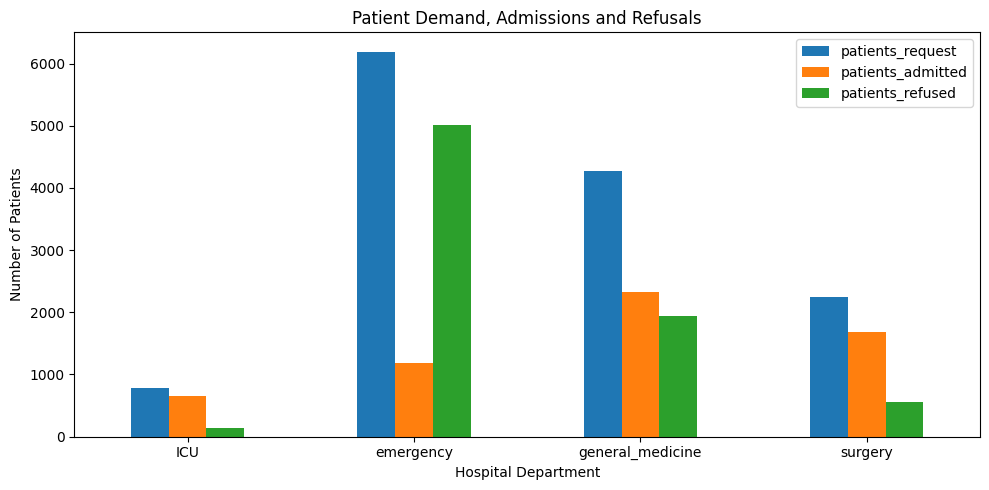

In [9]:

# Step 8: Chart 1 - Department-wise patient analysis

department_summary[
    ["patients_request",
     "patients_admitted",
     "patients_refused"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Patient Demand, Admissions and Refusals")
plt.xlabel("Hospital Department")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()


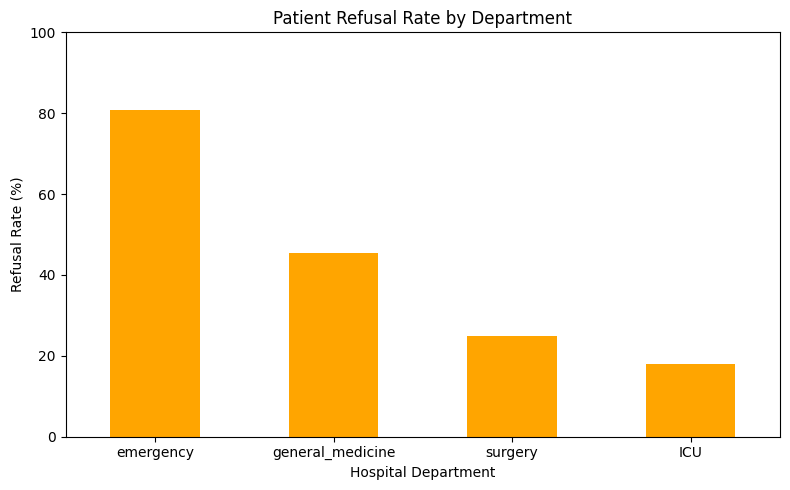

In [10]:

# Chart 2: Department-wise refusal rate

department_summary["refusal_rate"].sort_values(
    ascending=False
).plot(kind="bar", figsize=(8, 5), color="orange")

plt.title("Patient Refusal Rate by Department")
plt.xlabel("Hospital Department")
plt.ylabel("Refusal Rate (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


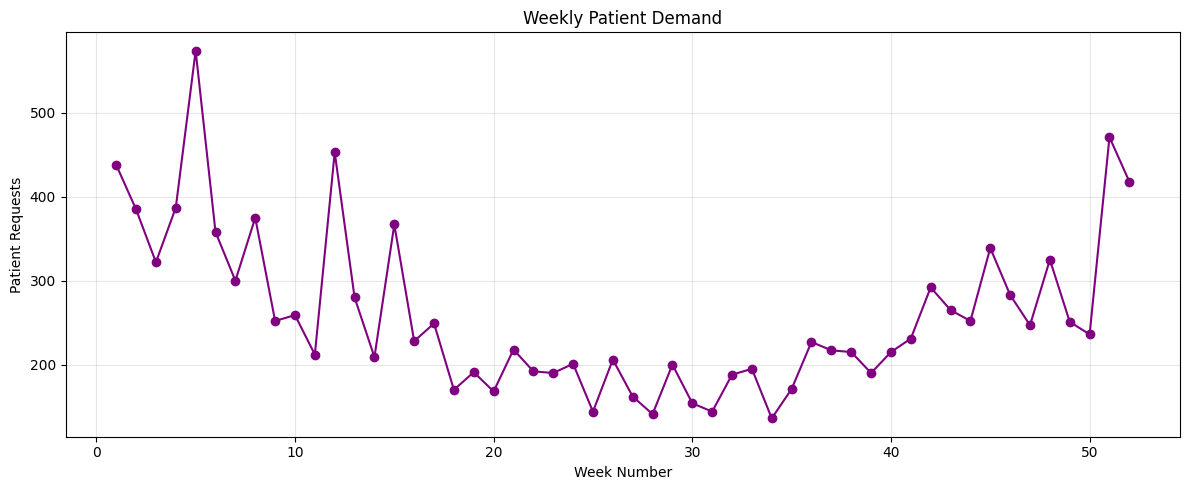

In [11]:

# Chart 3: Weekly patient demand

weekly_demand = services.groupby("week")["patients_request"].sum()

plt.figure(figsize=(12, 5))

plt.plot(weekly_demand.index,
         weekly_demand.values,
         marker="o",
         color="purple")

plt.title("Weekly Patient Demand")
plt.xlabel("Week Number")
plt.ylabel("Patient Requests")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Chart 3: Weekly Patient Demand – Interpretation

This line chart shows changes in total patient requests across 52 weeks.

The highest demand occurred in Week 5, with 574 patient requests, while the lowest demand occurred in Week 34, with 136 requests.

The average weekly demand was approximately 259 requests.

These results show that patient demand varies considerably throughout the year.

**Business Recommendation:** Hospital management should monitor weekly demand patterns and prepare flexible staffing and bed-allocation plans for periods of high demand.

**Limitation:** The chart identifies changes in demand but does not explain what caused those changes.


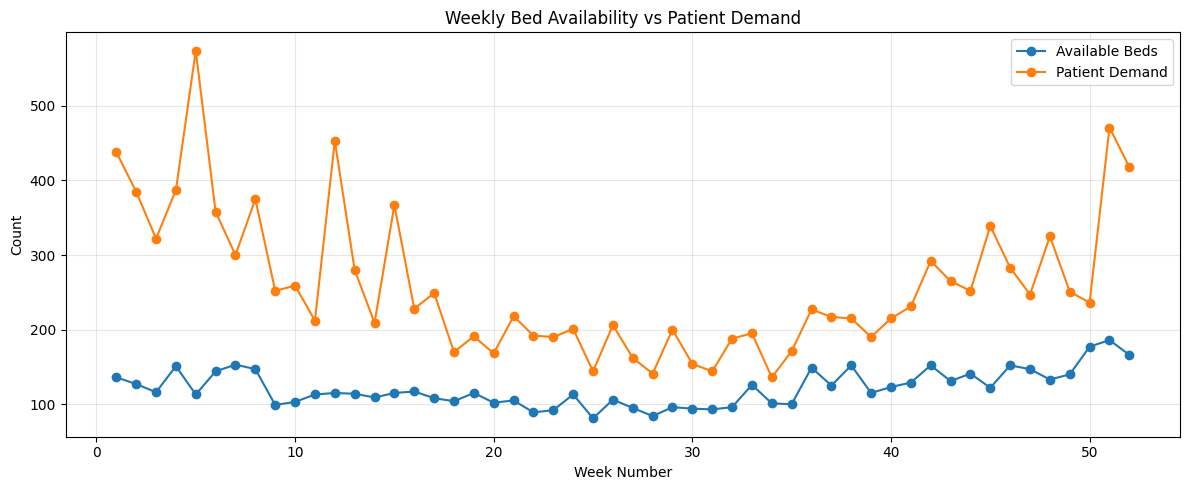

In [12]:

# Chart 4: Weekly bed availability vs patient demand

weekly_capacity = services.groupby("week")[
    ["available_beds", "patients_request"]
].sum()

weekly_capacity.plot(figsize=(12, 5), marker="o")

plt.title("Weekly Bed Availability vs Patient Demand")
plt.xlabel("Week Number")
plt.ylabel("Count")
plt.legend(["Available Beds", "Patient Demand"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Chart 4: Weekly Bed Availability vs Patient Demand – Interpretation

This line chart compares total weekly patient requests with available beds across the hospital departments.

The average weekly patient demand was approximately 259 requests, while the average number of available beds was approximately 121.

Patient requests exceeded the reported available beds in all 52 weeks.

In Week 5, patient demand reached 574 requests, compared with 113 available beds.

These findings suggest that hospital management should investigate whether the available capacity is sufficient to handle patient demand.

**Business Recommendation:** Hospital management should monitor patient demand, bed availability, admission patterns and discharge schedules to improve capacity planning.

**Limitation:** Patient requests and available beds are different operational measures. This comparison does not directly measure bed occupancy or prove a bed shortage because beds may be reused during the week.

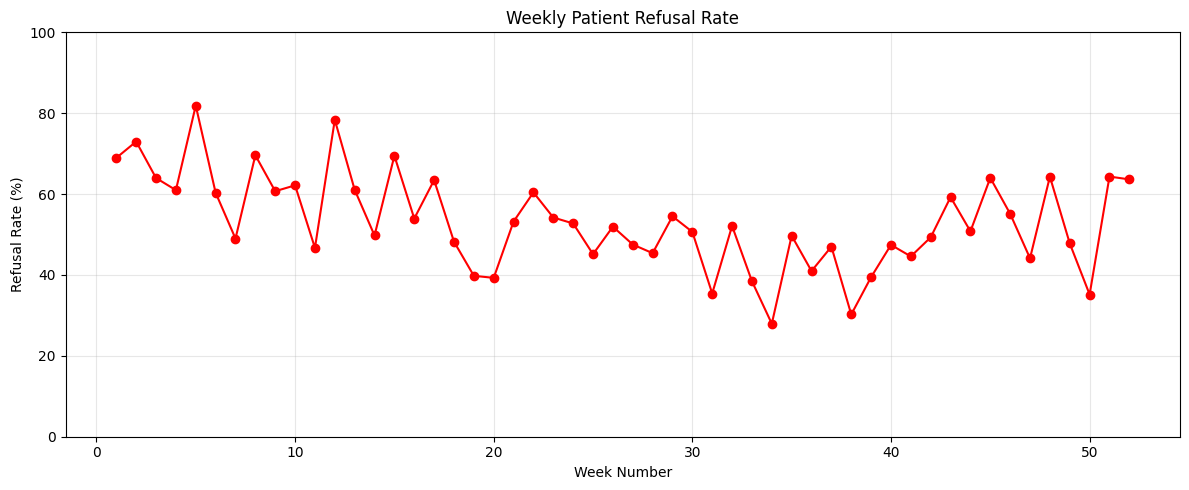

Highest refusal week: 5
Highest refusal rate: 81.88 %


In [13]:

# Chart 5: Weekly patient refusal rate

weekly_refusal = services.groupby("week")[
    ["patients_request", "patients_refused"]
].sum()

weekly_refusal["refusal_rate"] = (
    weekly_refusal["patients_refused"] /
    weekly_refusal["patients_request"]
) * 100

plt.figure(figsize=(12, 5))

plt.plot(weekly_refusal.index,
         weekly_refusal["refusal_rate"],
         marker="o", color="red")

plt.title("Weekly Patient Refusal Rate")
plt.xlabel("Week Number")
plt.ylabel("Refusal Rate (%)")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Highest refusal week:",
      weekly_refusal["refusal_rate"].idxmax())

print("Highest refusal rate:",
      round(weekly_refusal["refusal_rate"].max(), 2), "%")


### Chart 5: Weekly Patient Refusal Rate – Interpretation

This line chart shows the percentage of patient requests refused by the hospital across 52 weeks.

The highest refusal rate occurred in Week 5 at 81.88%, when 470 out of 574 patient requests were refused.

The lowest refusal rate occurred in Week 34 at 27.94%.

The average of the 52 weekly refusal rates was approximately 53.22%, while the overall hospital refusal rate was 56.64%. These figures differ because the overall rate considers the total number of patient requests.

**Business Recommendation:** Hospital management should investigate weeks with high refusal rates, review department-wise demand and bed availability, and improve admission planning.

**Limitation:** The chart identifies periods of high patient refusals but does not establish their underlying causes.

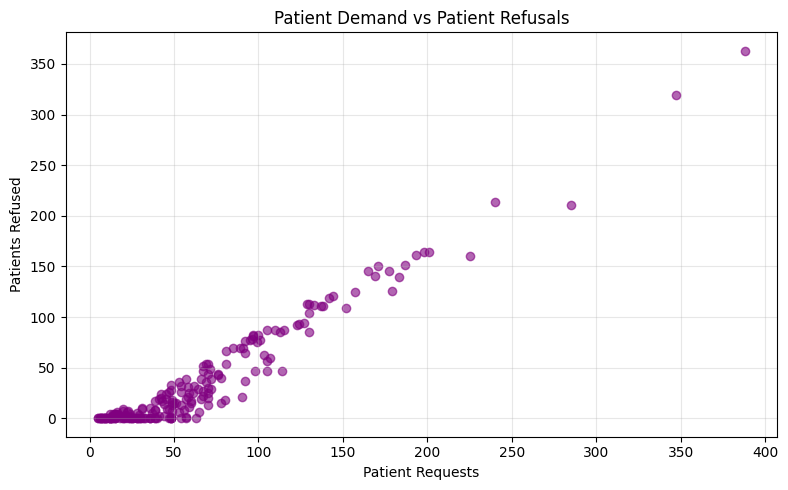

In [14]:

# Chart 6: Patient demand vs patient refusals

plt.figure(figsize=(8, 5))

plt.scatter(services["patients_request"],
            services["patients_refused"],
            color="purple", alpha=0.6)

plt.title("Patient Demand vs Patient Refusals")
plt.xlabel("Patient Requests")
plt.ylabel("Patients Refused")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Chart 6: Patient Demand vs Patient Refusals – Interpretation

This scatter plot shows the relationship between patient requests and patient refusals across 208 weekly department records.

The correlation coefficient is approximately +0.97, indicating a strong positive relationship.

Records with higher patient requests generally show higher patient refusals.

**Business Recommendation:** Hospital management should monitor periods of high patient demand and investigate whether bed capacity, staffing and admission processes can meet patient needs.

**Limitation:** Patient refusals are calculated from patient requests and admissions in this dataset. Therefore, the strong correlation partly reflects this mathematical relationship and does not independently establish the causes of patient refusals.

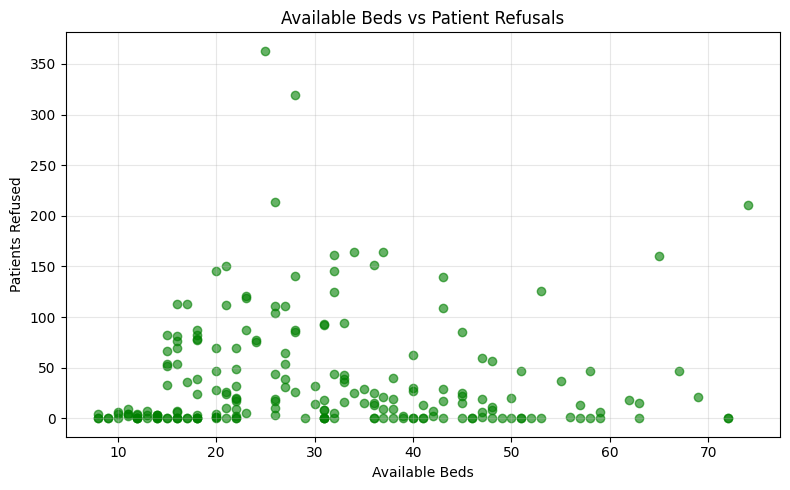

In [15]:

# Chart 7: Available beds vs patient refusals

plt.figure(figsize=(8, 5))

plt.scatter(services["available_beds"],
            services["patients_refused"],
            color="green", alpha=0.6)

plt.title("Available Beds vs Patient Refusals")
plt.xlabel("Available Beds")
plt.ylabel("Patients Refused")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Chart 7: Available Beds vs Patient Refusals – Interpretation

This scatter plot examines the relationship between available beds and patient refusals across 208 weekly department records.

The correlation coefficient is approximately +0.03, indicating a very weak positive linear relationship.

This means that available beds alone do not show a clear linear relationship with patient refusals across the dataset.

However, patient demand differs across hospital departments. Therefore, bed availability should be analysed together with patient requests and department-specific admission patterns.

**Business Recommendation:** Hospital management should monitor both patient demand and bed availability within each department to identify potential capacity problems.

**Limitation:** This chart does not establish whether increasing available beds would reduce patient refusals. Further department-wise analysis and operational data are required.

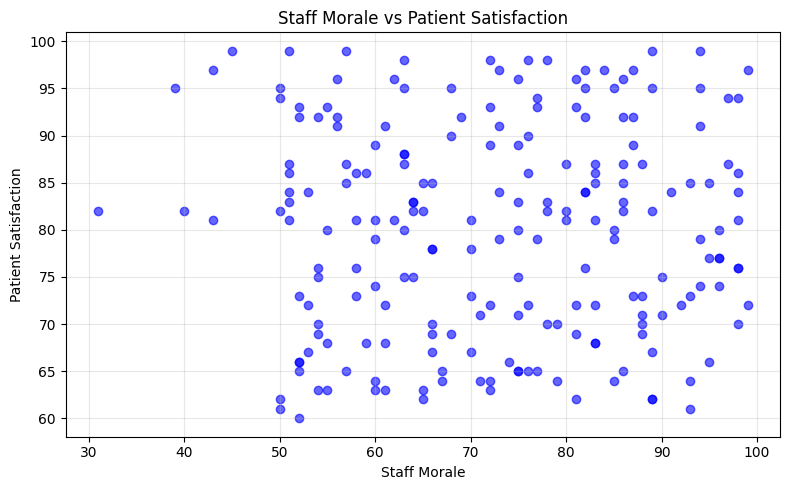

In [16]:

# Chart 8: Staff morale vs patient satisfaction

plt.figure(figsize=(8, 5))

plt.scatter(services["staff_morale"],
            services["patient_satisfaction"],
            color="blue", alpha=0.6)

plt.title("Staff Morale vs Patient Satisfaction")
plt.xlabel("Staff Morale")
plt.ylabel("Patient Satisfaction")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Chart 8: Staff Morale vs Patient Satisfaction – Interpretation

This scatter plot examines the relationship between staff morale and patient satisfaction across 208 weekly department records.

The correlation coefficient is approximately +0.01, indicating almost no linear relationship between these two variables in the dataset.

This suggests that changes in staff morale are not strongly associated with changes in patient satisfaction in the observed records.

**Business Recommendation:** Hospital management should monitor staff morale and patient satisfaction separately and investigate other factors that may influence patient experience, such as waiting times, communication and quality of care.

**Limitation:** This analysis does not prove that staff morale has no effect on patient satisfaction. Correlation alone cannot establish cause and effect, and other relevant factors may not be captured in the dataset.

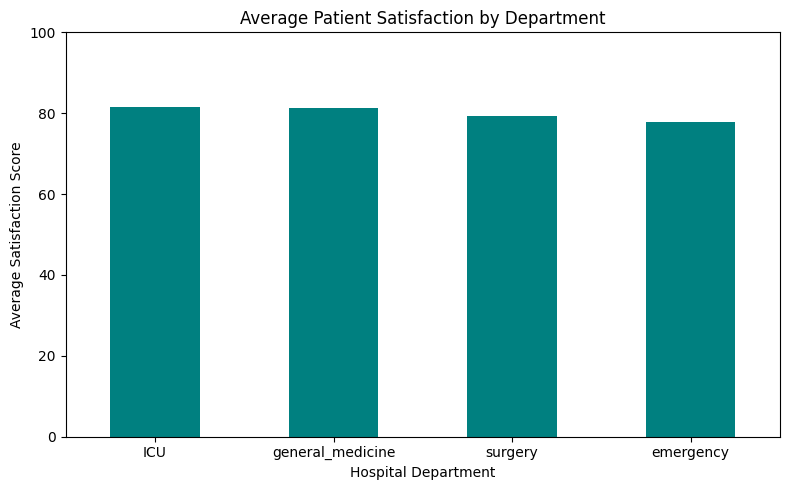

service
ICU                 81.62
general_medicine    81.23
surgery             79.27
emergency           77.88
Name: patient_satisfaction, dtype: float64


In [17]:

# Chart 9: Average patient satisfaction by department

avg_satisfaction = services.groupby("service")[
    "patient_satisfaction"
].mean().sort_values(ascending=False)

avg_satisfaction.plot(kind="bar",
                      figsize=(8, 5),
                      color="teal")

plt.title("Average Patient Satisfaction by Department")
plt.xlabel("Hospital Department")
plt.ylabel("Average Satisfaction Score")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

print(avg_satisfaction.round(2))


### Chart 9: Average Patient Satisfaction by Department – Interpretation

This bar chart compares average patient satisfaction scores across four hospital departments.

ICU recorded the highest average patient satisfaction score of 81.62, followed by General Medicine at 81.23 and Surgery at 79.27.

Emergency recorded the lowest average satisfaction score of 77.88.

The difference between the highest and lowest department scores was approximately 3.74 points.

**Business Recommendation:** Hospital management should review patient feedback and service processes in the Emergency department to identify opportunities for improving patient satisfaction.

**Limitation:** These scores describe differences between departments but do not explain their causes. Further investigation is needed before concluding why satisfaction differs.

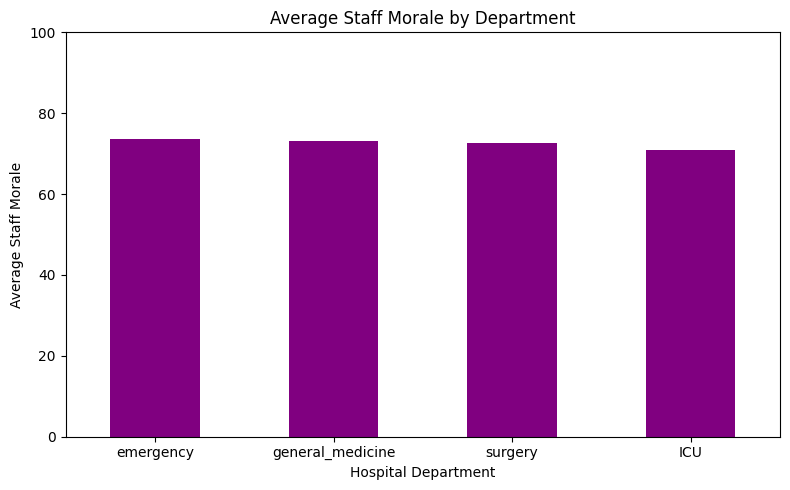

service
emergency           73.56
general_medicine    73.10
surgery             72.63
ICU                 70.98
Name: staff_morale, dtype: float64


In [18]:
avg_morale = services.groupby("service")["staff_morale"].mean().sort_values(ascending=False)

avg_morale.plot(kind="bar", figsize=(8, 5), color="purple")

plt.title("Average Staff Morale by Department")
plt.xlabel("Hospital Department")
plt.ylabel("Average Staff Morale")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

print(avg_morale.round(2))

### Chart 10: Average Staff Morale by Department – Interpretation

This bar chart compares average staff morale scores across four hospital departments.

Emergency recorded the highest average staff morale score of 73.56, followed by General Medicine at 73.10 and Surgery at 72.63.

ICU recorded the lowest average staff morale score of 70.98.

The difference between the highest and lowest department scores was approximately 2.58 points.

**Business Recommendation:** Hospital management should investigate staff working conditions, workload, shift schedules and employee feedback, particularly in the ICU department.

**Limitation:** The chart identifies differences in average staff morale but does not explain their causes. Further investigation and employee feedback are needed before making management decisions.

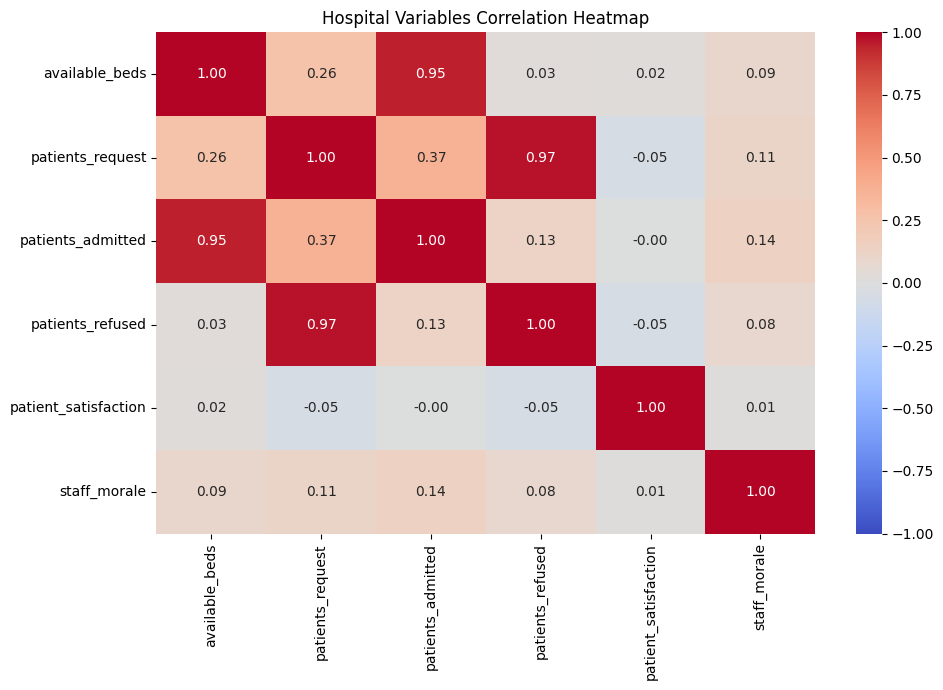

In [19]:
# Chart 11: Correlation Heatmap

plt.figure(figsize=(10, 7))

correlation = services[
    ["available_beds",
     "patients_request",
     "patients_admitted",
     "patients_refused",
     "patient_satisfaction",
     "staff_morale"]
].corr()

sns.heatmap(correlation,
            annot=True,
            cmap="coolwarm",
            fmt=".2f",
            vmin=-1,
            vmax=1)

plt.title("Hospital Variables Correlation Heatmap")
plt.tight_layout()
plt.show()

### Chart 11: Correlation Heatmap – Interpretation

This heatmap shows the correlation between six important hospital variables: available beds, patient requests, patients admitted, patients refused, patient satisfaction and staff morale.

**Key Findings:**

1. Patient requests and patient refusals have a strong positive correlation of approximately +0.97.
2. Available beds and patients admitted have a strong positive correlation of approximately +0.95.
3. Available beds and patient refusals have a very weak positive correlation of approximately +0.03.
4. Staff morale and patient satisfaction have almost no linear correlation, approximately +0.01.

**Business Recommendation:** Hospital management should monitor patient demand, admissions, refusals and bed availability together when planning hospital capacity. Staff morale and patient satisfaction should also be monitored separately.

**Limitation:** Correlation does not prove causation. Some strong relationships in this dataset reflect the mathematical calculations used to determine admissions and refusals. Further operational evidence is needed before making management decisions.

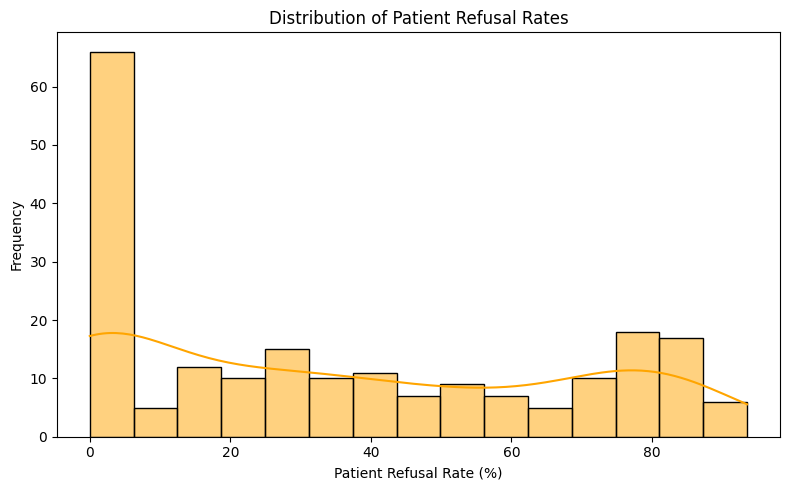

count    208.00
mean      35.08
std       31.61
min        0.00
25%        0.00
50%       28.91
75%       68.05
max       93.56
Name: refusal_rate, dtype: float64


In [20]:
# Chart 12: Patient Refusal Rate Distribution

services["refusal_rate"] = (
    services["patients_refused"] /
    services["patients_request"].replace(0, float("nan"))
) * 100

plt.figure(figsize=(8, 5))

sns.histplot(services["refusal_rate"],
             bins=15,
             kde=True,
             color="orange")

plt.title("Distribution of Patient Refusal Rates")
plt.xlabel("Patient Refusal Rate (%)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print(services["refusal_rate"].describe().round(2))

### Chart 12: Patient Refusal Rate Distribution – Interpretation

This histogram shows the distribution of patient refusal rates across 208 weekly department records.

The average refusal rate was 35.08%, while the median refusal rate was 28.91%.

The lowest recorded refusal rate was 0%, and the highest was 93.56%. This indicates considerable variation in refusal rates across the observations.

The overall hospital refusal rate was 56.64%, calculated by dividing 7,642 total refusals by 13,493 total patient requests.

The average of 35.08% gives equal weight to each weekly department record, while the overall rate of 56.64% considers the total number of patient requests.

**Business Recommendation:** Hospital management should identify departments and weeks with unusually high refusal rates and investigate their admission processes, patient demand and bed availability.

**Limitation:** The histogram shows how refusal rates are distributed but does not identify the causes of high refusal rates. Further department-wise and operational analysis is necessary.

### Understanding the Refusal Rate Calculations

The average refusal rate across the 208 weekly department records is 35.08%. However, the overall hospital refusal rate is 56.64%, calculated by dividing 7,642 total refusals by 13,493 total patient requests.

These figures are different because the first calculation gives equal weight to each weekly department record, while the second calculation considers the total number of patient requests.

For evaluating the overall proportion of patient requests refused, I use the overall refusal rate of 56.64%.

In [21]:
# Multiple Linear Regression Without Interaction

import statsmodels.formula.api as smf

model1 = smf.ols(
    formula="patients_refused ~ patients_request + available_beds + staff_morale + C(service)",
    data=services
).fit()

print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:       patients_refused   R-squared:                       0.995
Model:                            OLS   Adj. R-squared:                  0.995
Method:                 Least Squares   F-statistic:                     6894.
Date:                Tue, 24 Nov 2026   Prob (F-statistic):          1.00e-229
Time:                        16:48:57   Log-Likelihood:                -573.72
No. Observations:                 208   AIC:                             1161.
Df Residuals:                     201   BIC:                             1185.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept   

In [22]:
# Multiple Linear Regression With Interaction

model2 = smf.ols(
    formula="patients_refused ~ patients_request * available_beds + staff_morale + C(service)",
    data=services
).fit()

print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:       patients_refused   R-squared:                       0.995
Model:                            OLS   Adj. R-squared:                  0.995
Method:                 Least Squares   F-statistic:                     6163.
Date:                Tue, 24 Nov 2026   Prob (F-statistic):          8.02e-230
Time:                        16:50:07   Log-Likelihood:                -568.85
No. Observations:                 208   AIC:                             1154.
Df Residuals:                     200   BIC:                             1180.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept 

In [23]:
# Comparison of both regression models

import numpy as np

comparison = pd.DataFrame({
    "Model": ["Without Interaction", "With Interaction"],
    "R-squared": [model1.rsquared, model2.rsquared],
    "Adjusted R-squared": [
        model1.rsquared_adj,
        model2.rsquared_adj
    ],
    "AIC": [model1.aic, model2.aic],
    "BIC": [model1.bic, model2.bic],
    "RMSE": [
        np.sqrt(np.mean(model1.resid**2)),
        np.sqrt(np.mean(model2.resid**2))
    ]
})

display(comparison.round(6))

,Model,R-squared,Adjusted R-squared,AIC,BIC,RMSE
0,Without Interaction,0.995164,0.995020,1161.445376,1184.808142,3.816538
1,With Interaction,0.995386,0.995224,1153.705695,1180.406000,3.728220


### Regression Model Interpretation and Limitations

I developed two multiple linear regression models to analyse patient refusals. The first model used patient requests, available beds, staff morale and hospital departments. The second model included an interaction between patient requests and available beds.

Both models achieved an R² of approximately 0.995. The second model performed slightly better, with a lower RMSE and AIC.

However, these results should be interpreted carefully. Patient refusals are closely related to patient requests and admissions, which may contribute to the high R² values.

The models also use observational data, so the results show statistical relationships rather than proving cause and effect.

I recommend using these findings to support hospital planning decisions rather than treating the models as fully validated forecasting tools. Further testing with separate data would be needed to evaluate their predictive performance.Another important limitation is that patient refusals are calculated from patient requests and admissions. Since these variables are mathematically related, the high R² should not be interpreted as evidence that the model can independently predict future hospital demand.### Additional Interpretation of the Interaction Model

In the second regression model, the interaction coefficient between patient requests and available beds is approximately -0.0011, with a p-value of 0.002.

This suggests that the relationship between patient requests and predicted refusals varies depending on bed availability. The negative interaction coefficient indicates that the association between additional patient requests and refusals becomes slightly weaker as available beds increase.

However, the model has a high condition number of approximately 22,500, which may indicate multicollinearity or numerical problems. Therefore, the individual regression coefficients should be interpreted carefully.

Although the interaction model performs slightly better on the analysed data, further testing is needed before using it to predict future admission refusals.n this dataset, admissions are calculated as the minimum of patient requests and available beds, while refusals equal requests minus admissions. Therefore, the very high R² mainly reflects a built-in mathematical relationship rather than independently validated forecasting ability.

### Business Solution 1: Emergency Department Capacity Improvement

The analysis shows that the emergency department has the highest patient refusal rate of 80.87%. Out of 6,193 patient requests, 5,008 were refused.

I recommend that hospital management review emergency bed availability, staffing requirements and patient demand. This can help management identify capacity gaps and reduce patient refusals without compromising other departments.

The effectiveness of this solution can be measured by monitoring the emergency department's patient refusal rate.

### Business Solution 2: Better Bed Capacity Planning

My analysis shows a strong positive correlation (0.97) between patient requests and refusals. I also found a strong relationship (0.95) between available beds and patient admissions.

I recommend that hospital management monitor weekly patient demand and plan bed availability accordingly. They should also review discharge schedules and identify periods when additional capacity may be needed.

The expected benefit is better resource utilisation and fewer admission refusals.

**KPI:** Weekly patient refusal rate and bed utilisation.

### Business Solution 3: Improving Patient Satisfaction
My analysis shows that the Emergency department has the lowest average patient satisfaction score of 77.88, compared to other departments.

I recommend that hospital management improve patient communication, review waiting times and introduce a better complaint-handling system. These steps may help improve patient experience and satisfaction.

Responsible: Emergency Department Manager
Timeline: 30 days
Expected Benefit: Higher patient satisfaction and better service quality.
KPI: Average patient satisfaction score.

### Business Solution 4: Improving Staff Morale

My analysis shows that the ICU department has the lowest average staff morale among the four hospital departments. I also found that the correlation between staff morale and patient satisfaction is very weak (0.01).

I recommend that hospital management review ICU staff workloads, shift schedules and working conditions. Management should also collect employee feedback to understand the reasons for lower morale.

**Responsible:** HR Manager and ICU Department Head

**Timeline:** 30 days

**Expected Benefit:** Improved employee well-being and better working conditions.

**KPI:** Average ICU staff morale score.

### Business Solution 5: Improving Hospital Admission Efficiency
Finding: The hospital refused 7,642 out of 13,493 patient requests, resulting in a 56.64% refusal rate.

Recommendation: Develop a weekly hospital performance dashboard to track admission demand, refusals and available beds.

Responsible: Hospital Operations Manager and Data Analyst

Timeline: 30 days

Expected Benefit: Faster identification of admission problems and improved capacity planning.

KPI: Overall patient refusal rate and admission rate.

## Integrated Managerial Recommendations

Based on my Python analysis of the Hospital Beds Management dataset, I recommend the following actions to improve hospital operations.

**1. Prioritise the Emergency Department:** The Emergency department has the highest patient refusal rate of 80.87%. Hospital management should investigate capacity shortages and review admission procedures.

**2. Improve Bed Capacity Planning:** The analysis shows a strong positive correlation (0.97) between patient requests and refusals. Management should monitor weekly demand and plan bed availability according to patient requirements.

**3. Improve Patient Satisfaction:** The Emergency department has the lowest average patient satisfaction score of 77.88. Management should review waiting times, patient communication and complaint handling.

**4. Focus on ICU Staff Morale:** ICU has the lowest average staff morale among the departments. The HR team should review employee workloads, shift schedules and working conditions.

**5. Introduce a Weekly Performance Dashboard:** The hospital should monitor patient requests, admissions, refusals and bed availability through a simple dashboard to support faster decision-making.

### Conclusion

My analysis suggests that patient demand and bed availability are important factors associated with hospital admission outcomes. The regression model with interaction terms performed slightly better than the model without interaction terms.

I recommend that hospital management first investigate the high refusal rate in the Emergency department, followed by improvements in bed planning, patient satisfaction and staff management.

These recommendations are based on statistical relationships and should be evaluated before implementation.

## SQL Analysis – Hospital Beds Management

In [24]:

import sqlite3
import pandas as pd

# Create a SQLite database
conn = sqlite3.connect("hospital_management.db")

# Import CSV files into database tables
patients = pd.read_csv("patients.csv")
services = pd.read_csv("services_weekly.csv")
staff = pd.read_csv("staff.csv")
schedule = pd.read_csv("staff_schedule.csv")

patients.to_sql("patients", conn, if_exists="replace", index=False)
services.to_sql("services_weekly", conn, if_exists="replace", index=False)
staff.to_sql("staff", conn, if_exists="replace", index=False)
schedule.to_sql("staff_schedule", conn, if_exists="replace", index=False)

print("Hospital database created successfully!")


Hospital database created successfully!


In [25]:

query = """
SELECT *
FROM services_weekly
LIMIT 5;
"""

result = pd.read_sql_query(query, conn)
display(result)


,week,month,service,available_beds,patients_request,patients_admitted,patients_refused,patient_satisfaction,staff_morale,event
0,1,1,emergency,32,76,32,44,67,70,none
1,1,1,surgery,45,130,45,85,83,78,flu
2,1,1,general_medicine,37,201,37,164,97,43,flu
3,1,1,ICU,22,31,22,9,84,91,flu
4,2,1,emergency,28,169,28,141,75,64,none


### SQL Query 1: Exploring Hospital Services Data

**Business Question:** What information is available in the weekly hospital services table?

**SQL Technique:** SELECT, FROM and LIMIT.

**Interpretation:** I used SQL to display the first five records from the hospital services table. This helped me understand the available variables before performing further analysis.

In [26]:

query = """
SELECT COUNT(*) AS total_records
FROM services_weekly;
"""

result = pd.read_sql_query(query, conn)
display(result)


,total_records
0,208


### SQL Query 2: Counting Hospital Service Records

**Business Question:** How many records are available in the weekly hospital services dataset?

**SQL Technique:** COUNT(*).

**Interpretation:** I used the COUNT function to calculate the total number of records in the services_weekly table. The dataset contains 208 weekly service records, which are used for further hospital performance analysis.

In [27]:

query = """
SELECT
    service,
    COUNT(*) AS total_records
FROM services_weekly
GROUP BY service
ORDER BY service;
"""

result = pd.read_sql_query(query, conn)
display(result)


,service,total_records
0,ICU,52
1,emergency,52
2,general_medicine,52
3,surgery,52


### SQL Query 3: Department-wise Record Count

**Business Question:** How many weekly service records are available for each hospital department?

**SQL Technique:** COUNT(), GROUP BY and ORDER BY.

**Interpretation:** I used GROUP BY to organise the hospital records according to department. The analysis shows 52 weekly records for each of the four departments, giving a total of 208 records. This indicates that all four departments have equal numbers of weekly observations in the dataset.

In [29]:

query = """
SELECT
    service,
    SUM(patients_request) AS total_requests,
    SUM(patients_admitted) AS total_admitted,
    SUM(patients_refused) AS total_refused
FROM services_weekly
GROUP BY service
ORDER BY total_refused DESC;
"""

result = pd.read_sql_query(query, conn)
display(result)


,service,total_requests,total_admitted,total_refused
0,emergency,6193,1185,5008
1,general_medicine,4270,2332,1938
2,surgery,2241,1686,555
3,ICU,789,648,141


### SQL Query 4: Department-wise Patient Admission Analysis

**Business Question:** Which hospital department receives the highest patient demand and records the most admission refusals?

**SQL Technique:** SUM(), GROUP BY and ORDER BY.

**Interpretation:** I used SQL to calculate total patient requests, admissions and refusals for each hospital department. The Emergency department received the highest number of patient requests (6,193) and recorded the highest number of refusals (5,008).

This finding suggests that hospital management should prioritise investigating admission capacity and operational challenges in the Emergency department.

In [30]:

query = """
SELECT
    service,
    SUM(patients_request) AS total_requests,
    SUM(patients_refused) AS total_refused,
    ROUND(
        100.0 * SUM(patients_refused) /
        NULLIF(SUM(patients_request), 0),
        2
    ) AS refusal_rate
FROM services_weekly
GROUP BY service
ORDER BY refusal_rate DESC;
"""

result = pd.read_sql_query(query, conn)
display(result)


,service,total_requests,total_refused,refusal_rate
0,emergency,6193,5008,80.87
1,general_medicine,4270,1938,45.39
2,surgery,2241,555,24.77
3,ICU,789,141,17.87


### SQL Query 5: Department-wise Patient Refusal Rate

**Business Question:** Which hospital department has the highest patient refusal rate?

**SQL Technique:** SUM(), ROUND(), NULLIF(), GROUP BY and ORDER BY.

**Interpretation:** I calculated the patient refusal rate for each department by dividing total refusals by total requests and multiplying by 100.

The Emergency department has the highest refusal rate at 80.87%, followed by General Medicine at 45.39%, Surgery at 24.77% and ICU at 17.87%.

This suggests that Emergency should be the first department investigated for admission capacity and operational improvements.

In [31]:

query = """
SELECT
    service,
    ROUND(AVG(patient_satisfaction), 2)
        AS average_satisfaction
FROM services_weekly
GROUP BY service
ORDER BY average_satisfaction ASC;
"""

result = pd.read_sql_query(query, conn)
display(result)


,service,average_satisfaction
0,emergency,77.88
1,surgery,79.27
2,general_medicine,81.23
3,ICU,81.62


### SQL Query 6: Department-wise Patient Satisfaction

**Business Question:** Which hospital department has the lowest average patient satisfaction score?

**SQL Technique:** AVG(), ROUND(), GROUP BY and ORDER BY.

**Interpretation:** I used the AVG function to calculate the average patient satisfaction score for each hospital department.

The Emergency department has the lowest average satisfaction score of 77.88, followed by Surgery at 79.27, General Medicine at 81.23 and ICU at 81.62.

I recommend that hospital management investigate the patient experience in the Emergency department, particularly communication, waiting procedures and complaint handling.

In [32]:

query = """
SELECT
    service,
    ROUND(AVG(staff_morale), 2)
        AS average_staff_morale
FROM services_weekly
GROUP BY service
ORDER BY average_staff_morale ASC;
"""

result = pd.read_sql_query(query, conn)
display(result)


,service,average_staff_morale
0,ICU,70.98
1,surgery,72.63
2,general_medicine,73.10
3,emergency,73.56


### SQL Query 7: Department-wise Staff Morale

**Business Question:** Which hospital department has the lowest average staff morale score?

**SQL Technique:** AVG(), ROUND(), GROUP BY and ORDER BY.

**Interpretation:** I used SQL to calculate the average staff morale score for each hospital department.

The ICU department recorded the lowest average staff morale score, approximately 70.98.

This finding suggests that hospital management should review ICU employee workloads, shift schedules and working conditions. Employee feedback may help identify the reasons for lower morale.

In [33]:

query = """
SELECT
    week,
    service,
    patients_request,
    patients_admitted,
    patients_refused
FROM services_weekly
WHERE patients_refused > 50
ORDER BY patients_refused DESC;
"""

result = pd.read_sql_query(query, conn)
display(result)


,week,service,patients_request,patients_admitted,patients_refused
0,5,emergency,388,25,363
1,12,emergency,347,28,319
2,8,emergency,240,26,214
3,51,general_medicine,285,74,211
4,1,general_medicine,201,37,164
5,6,emergency,198,34,164
6,45,emergency,193,32,161
7,52,general_medicine,225,65,160
8,46,emergency,187,36,151
9,43,emergency,171,21,150


### SQL Query 8: Identifying High Patient Refusal Records

**Business Question:** Which weekly hospital service records have more than 50 patient refusals?

**SQL Technique:** SELECT, WHERE and ORDER BY.

**Interpretation:** I used the WHERE clause to identify hospital service records with more than 50 patient refusals. I arranged the results in descending order to examine the records with the highest refusal counts first.

This analysis can help hospital management identify periods and departments that require further investigation into patient demand and bed availability.

In [34]:

query = """
SELECT
    service,
    COUNT(*) AS high_refusal_records
FROM services_weekly
WHERE patients_refused > 50
GROUP BY service
ORDER BY high_refusal_records DESC;
"""

result = pd.read_sql_query(query, conn)
display(result)



,service,high_refusal_records
0,emergency,41
1,general_medicine,10
2,surgery,2


### SQL Query 9: Department-wise High Refusal Records

**Business Question:** How many weekly service records in each department have more than 50 patient refusals?

**SQL Technique:** WHERE, COUNT(), GROUP BY and ORDER BY.

**Interpretation:** I used WHERE to filter hospital service records with more than 50 patient refusals. I then used COUNT and GROUP BY to calculate how frequently this occurred in each department.

This analysis helps identify departments that repeatedly experience high numbers of admission refusals and may require additional operational investigation.The SQL results show that Emergency had 41 weekly records with more than 50 patient refusals, followed by General Medicine with 10 and Surgery with 2. ICU had no records above this threshold.

This indicates that high patient refusals occur most frequently in the Emergency department, supporting my earlier recommendation to prioritise its admission capacity and operational processes.

In [35]:

query = """
SELECT
    service,
    ROUND(AVG(available_beds), 2) AS average_beds,
    MIN(available_beds) AS minimum_beds,
    MAX(available_beds) AS maximum_beds
FROM services_weekly
GROUP BY service
ORDER BY average_beds DESC;
"""

result = pd.read_sql_query(query, conn)
display(result)


,service,average_beds,minimum_beds,maximum_beds
0,general_medicine,46.23,26,74
1,surgery,37.52,18,63
2,emergency,22.79,15,36
3,ICU,14.85,8,23


### SQL Query 10: Department-wise Bed Availability

**Business Question:** Which hospital department has the highest and lowest average number of available beds?

**SQL Technique:** AVG(), MIN(), MAX(), ROUND(), GROUP BY and ORDER BY.

**Interpretation:** I used SQL to calculate the average, minimum and maximum available beds for each hospital department.

General Medicine has the highest average bed availability at 46.23 beds, followed by Surgery at 37.52, Emergency at 22.79 and ICU at 14.85.

Although ICU has the lowest average bed availability, Emergency records the highest patient refusal rate. This suggests that admission challenges may depend on patient demand and other operational factors, not just the number of available beds.

I recommend that hospital management monitor patient demand and bed availability together to support better capacity planning.

In [36]:

query = """
SELECT
    service,
    ROUND(AVG(patients_request), 2)
        AS average_weekly_requests,
    ROUND(AVG(available_beds), 2)
        AS average_available_beds,
    ROUND(
        1.0 * SUM(patients_request) /
        NULLIF(SUM(available_beds), 0),
        2
    ) AS demand_bed_ratio
FROM services_weekly
GROUP BY service
ORDER BY demand_bed_ratio DESC;
"""

result = pd.read_sql_query(query, conn)
display(result)


,service,average_weekly_requests,average_available_beds,demand_bed_ratio
0,emergency,119.10,22.79,5.23
1,general_medicine,82.12,46.23,1.78
2,surgery,43.10,37.52,1.15
3,ICU,15.17,14.85,1.02


### SQL Query 11: Patient Demand and Bed Availability

**Business Question:** Which hospital department faces the highest patient demand relative to available beds?

**SQL Technique:** AVG(), SUM(), ROUND(), NULLIF(), GROUP BY and ORDER BY.

**Interpretation:** I used SQL to compare average weekly patient requests with average available beds across the four hospital departments.

Emergency has the highest demand-to-bed ratio of 5.23, followed by General Medicine at 1.78, Surgery at 1.15 and ICU at 1.02.

This suggests that Emergency experiences the highest patient demand relative to its available beds. The finding supports my earlier recommendation to investigate Emergency admission capacity and improve weekly bed planning.

The demand-to-bed ratio is an operational indicator and should not be treated as a direct measure of bed occupancy.

In [37]:

query = """
SELECT
    s.week,
    s.service,
    s.patients_refused,
    COUNT(*) AS scheduled_staff_records,
    SUM(
        CASE WHEN sch.present = 1
        THEN 1 ELSE 0 END
    ) AS staff_present
FROM services_weekly AS s
INNER JOIN staff_schedule AS sch
    ON s.week = sch.week
    AND s.service = sch.service
GROUP BY
    s.week,
    s.service,
    s.patients_refused
ORDER BY s.patients_refused DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
display(result)


,week,service,patients_refused,scheduled_staff_records,staff_present
0,5,emergency,363,39,35
1,12,emergency,319,39,0
2,8,emergency,214,39,36
3,51,general_medicine,211,28,0
4,1,general_medicine,164,28,27
5,6,emergency,164,39,0
6,45,emergency,161,39,0
7,52,general_medicine,160,28,23
8,46,emergency,151,39,31
9,43,emergency,150,39,35


### SQL Query 12: Patient Refusals and Staff Availability

**Business Question:** Which weekly hospital service records have the highest patient refusals, and what staffing information was recorded?

**SQL Technique:** SELECT, INNER JOIN, COUNT(), SUM(), CASE WHEN, GROUP BY, ORDER BY and LIMIT.

**Interpretation:**

I used INNER JOIN to combine the weekly hospital services data with staff schedule records using the week and department columns.

I used COUNT to calculate the number of matching schedule records and SUM with CASE WHEN to count records where staff presence was marked as 1.

The results show that Emergency appears in seven of the ten records with the highest patient refusals. The highest refusal count was 363 in Emergency during Week 5.

Some records show zero staff presence even though schedule records exist. These observations should be verified because they may reflect staffing issues or problems with the recorded data.

I recommend that hospital management investigate periods with high patient refusals and review the corresponding staffing information.

**Limitation:** The staffing figures represent schedule records and presence indicators. They should not automatically be interpreted as the number of unique employees.### Staff Data Consistency and Limitations

I compared the staff master dataset (`staff.csv`) with the staff schedule dataset (`staff_schedule.csv`).

The staff master dataset contains 110 unique staff IDs, while the staff schedule dataset contains 126 unique staff IDs. No staff IDs match between the two datasets.

This indicates a data consistency problem. Therefore, the two datasets should not be directly joined using staff IDs without further verification.

SQL Query 12 remains useful because it combines weekly hospital services and staff schedule records using the week and department.

However, the staffing results should be interpreted as schedule records rather than verified unique employee counts.

I recommend that hospital management reconcile staff IDs and verify attendance records before using this information for staffing decisions.